Saving EAGLE.jpg to EAGLE.jpg


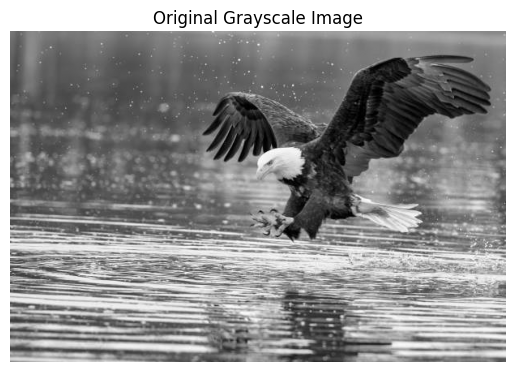

In [1]:
# Step 1: Import the required libraries and load a grayscale image

import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

uploaded = files.upload()

image_path = list(uploaded.keys())[0]

image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

if image is None:
    print("Error: Image not found.")
else:
    plt.imshow(image, cmap="gray")
    plt.title("Original Grayscale Image")
    plt.axis("off")
    plt.show()

In [2]:
# Step 2: Compute the Discrete Fourier Transform (DFT)

dft = np.fft.fft2(image)

In [3]:
# Step 3: Shift the zero-frequency component to the center

dft_shift = np.fft.fftshift(dft)

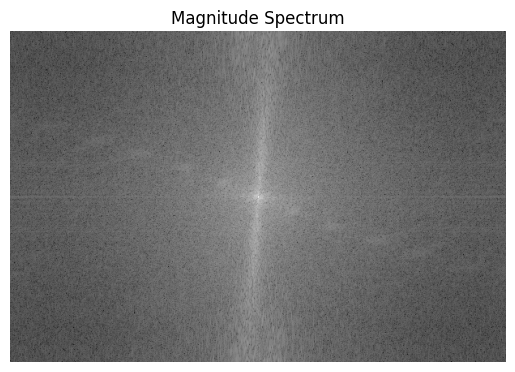

In [4]:
# Step 4: Display and analyze the magnitude spectrum

magnitude_spectrum = 20 * np.log(np.abs(dft_shift) + 1)

plt.imshow(magnitude_spectrum, cmap="gray")
plt.title("Magnitude Spectrum")
plt.axis("off")
plt.show()

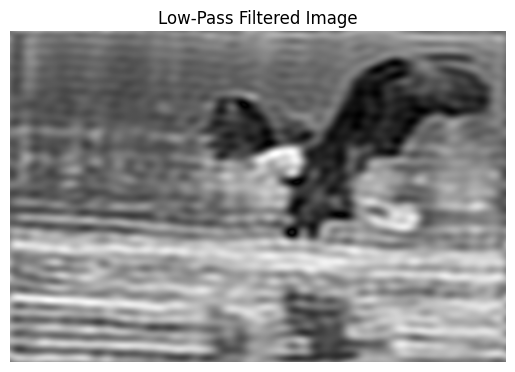

In [5]:
# Step 5: Apply a Low-Pass Frequency Filter

rows, cols = image.shape

crow, ccol = rows // 2, cols // 2

mask_low = np.zeros((rows, cols), np.uint8)

radius = 30

y, x = np.ogrid[:rows, :cols]

distance = np.sqrt((x - ccol) ** 2 + (y - crow) ** 2)

mask_low[distance <= radius] = 1

low_pass = dft_shift * mask_low

low_pass_shift = np.fft.ifftshift(low_pass)

low_pass_image = np.fft.ifft2(low_pass_shift)

low_pass_image = np.abs(low_pass_image)

low_pass_image = np.uint8(
    np.clip(low_pass_image, 0, 255)
)

plt.imshow(low_pass_image, cmap="gray")
plt.title("Low-Pass Filtered Image")
plt.axis("off")
plt.show()

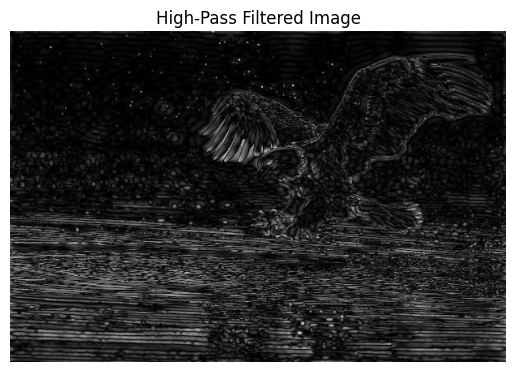

In [6]:
# Step 6: Apply a High-Pass Frequency Filter

mask_high = np.ones((rows, cols), np.uint8)

mask_high[distance <= radius] = 0

high_pass = dft_shift * mask_high

high_pass_shift = np.fft.ifftshift(high_pass)

high_pass_image = np.fft.ifft2(high_pass_shift)

high_pass_image = np.abs(high_pass_image)

high_pass_image = np.uint8(
    np.clip(high_pass_image, 0, 255)
)

plt.imshow(high_pass_image, cmap="gray")
plt.title("High-Pass Filtered Image")
plt.axis("off")
plt.show()

In [7]:
# Step 7: Perform the Inverse Fourier Transform

low_pass_reconstructed = np.fft.ifft2(
    np.fft.ifftshift(low_pass)
)

high_pass_reconstructed = np.fft.ifft2(
    np.fft.ifftshift(high_pass)
)

low_pass_reconstructed = np.abs(low_pass_reconstructed)
high_pass_reconstructed = np.abs(high_pass_reconstructed)

low_pass_reconstructed = np.uint8(
    np.clip(low_pass_reconstructed, 0, 255)
)

high_pass_reconstructed = np.uint8(
    np.clip(high_pass_reconstructed, 0, 255)
)

print("Inverse Fourier Transform completed successfully.")

Inverse Fourier Transform completed successfully.


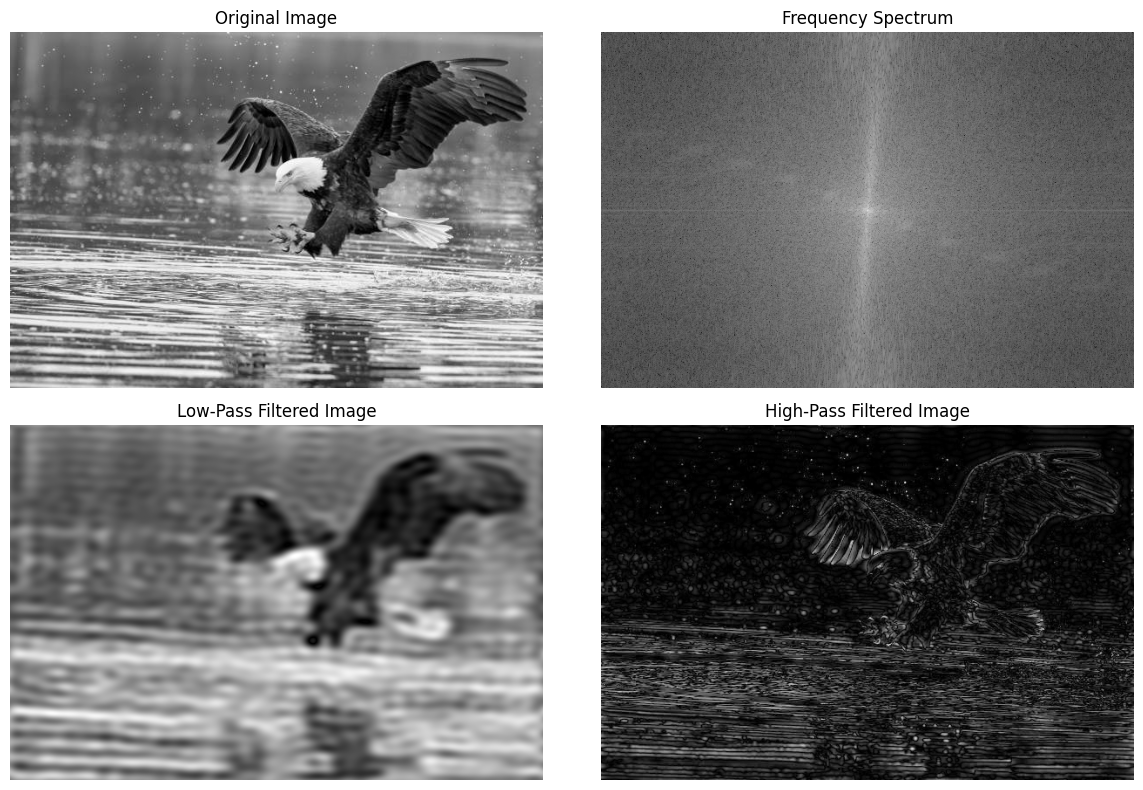

In [8]:
# Step 8: Compare the original image, frequency spectrum, low-pass filtered image, and high-pass filtered image

plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.imshow(image, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(magnitude_spectrum, cmap="gray")
plt.title("Frequency Spectrum")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(low_pass_reconstructed, cmap="gray")
plt.title("Low-Pass Filtered Image")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(high_pass_reconstructed, cmap="gray")
plt.title("High-Pass Filtered Image")
plt.axis("off")

plt.tight_layout()
plt.show()

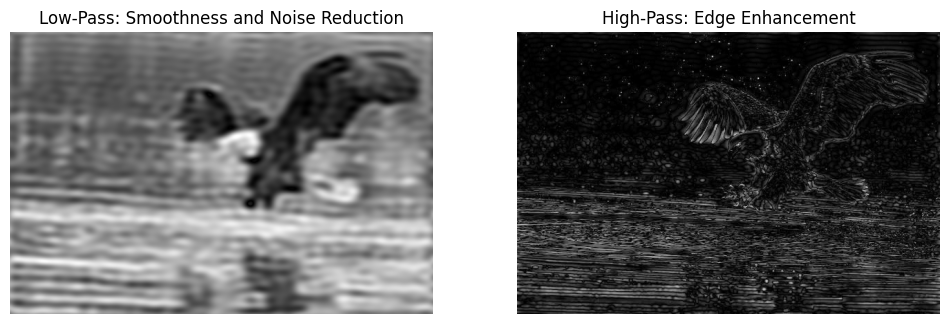

In [9]:
# Step 9: Analyze the impact of frequency domain filtering

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(low_pass_reconstructed, cmap="gray")
plt.title("Low-Pass: Smoothness and Noise Reduction")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(high_pass_reconstructed, cmap="gray")
plt.title("High-Pass: Edge Enhancement")
plt.axis("off")

plt.show()

In [10]:
# Step 10: Save the filtered images

cv2.imwrite("low_pass_filtered.jpg", low_pass_reconstructed)
cv2.imwrite("high_pass_filtered.jpg", high_pass_reconstructed)

print("Frequency domain filtering completed successfully.")
print("Low-pass and high-pass images have been saved.")

Frequency domain filtering completed successfully.
Low-pass and high-pass images have been saved.
